<a href="https://colab.research.google.com/github/Ahmettufan3310/74-musteri-segmentasyonu-rfm/blob/main/notebooks/08_churn_tahmini.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ucimlrepo -q
from ucimlrepo import fetch_ucirepo
import pandas as pd

df = fetch_ucirepo(id=352).data.original

temiz = df.dropna(subset=['CustomerID'])
temiz = temiz[~temiz['InvoiceNo'].astype(str).str.startswith('C')]
temiz = temiz[(temiz['Quantity'] > 0) & (temiz['UnitPrice'] > 0)]

cikar = ['POST', 'M', 'C2', 'DOT', 'BANK CHARGES', 'PADS']
temiz = temiz[~temiz['StockCode'].astype(str).isin(cikar)]

hatali = [('581483', '23843'), ('541431', '23166'), ('540815', '21108'), ('556444', '22502')]
for fatura, urun in hatali:
    temiz = temiz[~((temiz['InvoiceNo'].astype(str) == fatura) & (temiz['StockCode'].astype(str) == urun))]

temiz = temiz.drop_duplicates()
temiz['InvoiceDate'] = pd.to_datetime(temiz['InvoiceDate'])
temiz['Tutar'] = temiz['Quantity'] * temiz['UnitPrice']
print(len(temiz), temiz['CustomerID'].nunique())

391146 4333


In [2]:
kesim = pd.Timestamp('2011-09-09')
gecmis = temiz[temiz['InvoiceDate'] < kesim]
gelecek = temiz[temiz['InvoiceDate'] >= kesim]

print("Geçmiş :", gecmis['InvoiceDate'].min().date(), "-", gecmis['InvoiceDate'].max().date())
print("Gelecek:", gelecek['InvoiceDate'].min().date(), "-", gelecek['InvoiceDate'].max().date())

Geçmiş : 2010-12-01 - 2011-09-08
Gelecek: 2011-09-09 - 2011-12-09


Veri 9 Eylül 2011 tarihinden ikiye ayrıldı. Veri seti 9 Aralık 2011'de bittiği için son 3 ay "gelecek" olarak ayrıldı. Müşterinin bilgileri ilk 9 aydan çıkarıldı, son 3 ayda alışveriş yapıp yapmadığına bakılarak churn etiketi belirlendi.

In [3]:
def ozellik_cikar(veri, ref):
    o = veri.groupby('CustomerID').agg(
        Recency=('InvoiceDate', lambda x: (ref - x.max()).days),
        Frequency=('InvoiceNo', 'nunique'),
        Monetary=('Tutar', 'sum'),
        IlkAlisveris=('InvoiceDate', lambda x: (ref - x.min()).days),
        UrunCesidi=('StockCode', 'nunique'))
    o['OrtSepet'] = o['Monetary'] / o['Frequency']
    return o.reset_index()

veri = ozellik_cikar(gecmis, kesim)
veri['Churn'] = (~veri['CustomerID'].isin(gelecek['CustomerID'])).astype(int)

print(veri.shape)
print(veri['Churn'].value_counts())

(3359, 8)
Churn
0    1918
1    1441
Name: count, dtype: int64


9 Eylül'den önce alışveriş yapan 3.359 müşteri var. Bunların 1.441'i (%43) son 3 ayda hiç alışveriş yapmamış, yani churn olarak işaretlendi. Müşterilerin neredeyse yarısının kaybedilmesi işletme için yüksek bir oran. Sınıflar çok dengesiz olmasa da (%57 - %43) modelde class_weight='balanced' kullanıldı.

In [4]:
from sklearn.model_selection import train_test_split

ozellikler = ['Recency', 'Frequency', 'Monetary', 'IlkAlisveris', 'UrunCesidi', 'OrtSepet']
X = veri[ozellikler]
y = veri['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(len(X_train), len(X_test))

2519 840


In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

modeller = {
    'Lojistik Regresyon': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced')),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=5, class_weight='balanced', random_state=42)
}

sonuc = []
for ad, model in modeller.items():
    model.fit(X_train, y_train)
    tahmin = model.predict(X_test)
    olasilik = model.predict_proba(X_test)[:, 1]
    sonuc.append([ad, accuracy_score(y_test, tahmin), precision_score(y_test, tahmin),
                  recall_score(y_test, tahmin), f1_score(y_test, tahmin), roc_auc_score(y_test, olasilik)])

sonuc = pd.DataFrame(sonuc, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']).round(3)
print(sonuc)

                Model  Accuracy  Precision  Recall     F1  ROC-AUC
0  Lojistik Regresyon     0.670      0.587   0.778  0.669    0.735
1       Random Forest     0.676      0.596   0.758  0.667    0.744


İki model karşılaştırıldı. Random Forest (max_depth=5) ROC-AUC 0,744, Lojistik Regresyon 0,735 aldı; iki modelin sonuçları birbirine çok yakın. Bu projede asıl önemli olan recall, çünkü giden bir müşteriyi kaçırmak, kalacak müşteriye yanlışlıkla kampanya göndermekten daha maliyetli. Random Forest giden müşterilerin %75,8'ini yakalıyor. Derinlik denemesinden sonra max_depth 8'den 5'e düşürülünce recall 0,711'den 0,758'e çıktı.

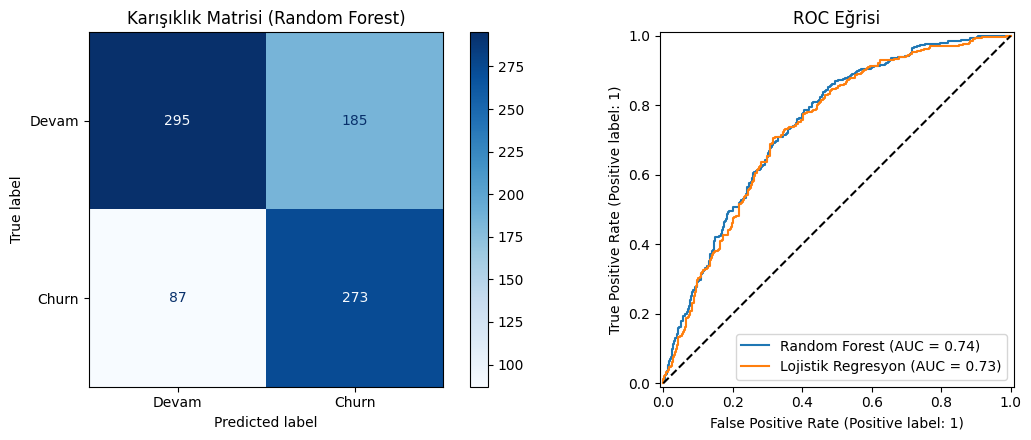

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

rf = modeller['Random Forest']

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, display_labels=['Devam', 'Churn'], cmap='Blues', ax=ax[0])
ax[0].set_title('Karışıklık Matrisi (Random Forest)')

RocCurveDisplay.from_estimator(rf, X_test, y_test, name='Random Forest', ax=ax[1])
RocCurveDisplay.from_estimator(modeller['Lojistik Regresyon'], X_test, y_test, name='Lojistik Regresyon', ax=ax[1])
ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set_title('ROC Eğrisi')
plt.tight_layout()
plt.show()

Test edilen 840 müşteriden gerçekte gidenlerin 273'ü doğru yakalandı, 87'si kaçırıldı. 185 müşteri ise aslında devam ettiği halde churn olarak tahmin edildi (yanlış alarm). ROC eğrisinde iki model neredeyse üst üste ve ikisi de rastgele tahmin çizgisinin belirgin şekilde üstünde.

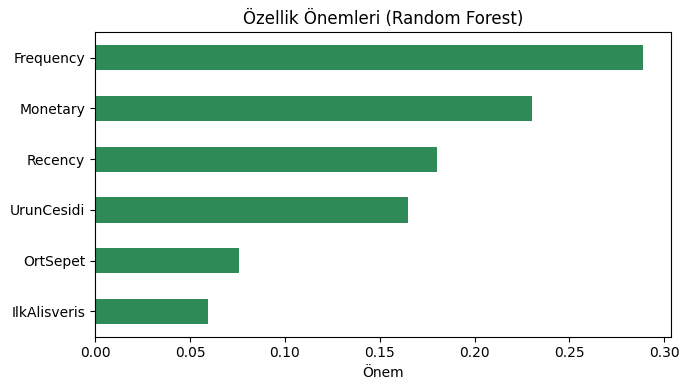

IlkAlisveris    0.059
OrtSepet        0.076
UrunCesidi      0.165
Recency         0.180
Monetary        0.231
Frequency       0.289
dtype: float64


In [14]:
onem = pd.Series(rf.feature_importances_, index=ozellikler).sort_values()

plt.figure(figsize=(7, 4))
onem.plot(kind='barh', color='seagreen')
plt.title('Özellik Önemleri (Random Forest)')
plt.xlabel('Önem')
plt.tight_layout()
plt.show()
print(onem.round(3))

En önemli özellik Frequency (0,289), ardından Monetary (0,231) ve Recency (0,180) geliyor. RFM'in üç değeri ilk üçte yer alıyor ve toplam önemin yaklaşık %70'ini oluşturuyor; bu, projede kullanılan RFM yaklaşımının churn tahmini için de anlamlı olduğunu gösteriyor. Yeni eklenen özelliklerden ürün çeşitliliği (0,165) de etkili çıktı, ortalama sepet ve müşteri süresi ise daha az etkili. Not: Random Forest'ın bu önem ölçüsü çok farklı değer alabilen sayısal sütunları biraz kayırabilir.

In [15]:
son_tarih = temiz['InvoiceDate'].max() + pd.Timedelta(days=1)
tum = ozellik_cikar(temiz, son_tarih)

tum['ChurnOlasiligi'] = rf.predict_proba(tum[ozellikler])[:, 1].round(3)
tum['Risk'] = pd.cut(tum['ChurnOlasiligi'], bins=[0, 0.4, 0.7, 1],
                     labels=['Düşük', 'Orta', 'Yüksek'], include_lowest=True)

seg = pd.read_csv('https://raw.githubusercontent.com/Ahmettufan3310/74-musteri-segmentasyonu-rfm/main/data/segment_sonuclari.csv')
tum = tum.merge(seg[['CustomerID', 'Segment']], on='CustomerID', how='left')

print(tum['Risk'].value_counts())
print((pd.crosstab(tum['Segment'], tum['Risk'], normalize='index') * 100).round(1))

Risk
Orta      2063
Düşük     1669
Yüksek     601
Name: count, dtype: int64
Risk             Düşük  Orta  Yüksek
Segment                             
Sadık             68.4  31.1     0.5
Uykuda             0.1  62.9    37.0
VIP               99.4   0.6     0.0
Yeni/Potansiyel   17.4  82.0     0.6


Model tüm 4.333 müşteriye uygulandı: 601 müşteri yüksek, 2.063 orta, 1.669 düşük riskli çıktı. VIP müşterilerin %99,4'ü düşük riskli, uykudaki müşterilerin %37'si yüksek riskli. Bu sonuç segment geçişi analiziyle (İP8) tutarlı: orada da VIP'lerin çok azı kaybedilmiş, uykudakilerin yarısına yakını geri dönmemişti. Yeni/Potansiyel müşterilerin %82'si orta riskte, yani bu grubun kalıp kalmayacağı belirsiz; kampanyalar için en uygun grup bu. Risk eşikleri (0,4 ve 0,7) yorumlamayı kolaylaştırmak için seçildi.

In [16]:
import joblib
joblib.dump(rf, 'churn_model.pkl')
tum.to_csv('churn_sonuclari.csv', index=False)
print("Kaydedildi")

Kaydedildi


## Deneyler

In [17]:
denemeler = {'60 gün': '2011-10-10', '90 gün': '2011-09-09', '120 gün': '2011-08-10'}
sonuc_gun = []
for ad, tarih in denemeler.items():
    k = pd.Timestamp(tarih)
    v = ozellik_cikar(temiz[temiz['InvoiceDate'] < k], k)
    v['Churn'] = (~v['CustomerID'].isin(temiz[temiz['InvoiceDate'] >= k]['CustomerID'])).astype(int)
    Xa, Xb, ya, yb = train_test_split(v[ozellikler], v['Churn'], test_size=0.25, random_state=42, stratify=v['Churn'])
    m = RandomForestClassifier(n_estimators=300, max_depth=8, class_weight='balanced', random_state=42).fit(Xa, ya)
    t = m.predict(Xb)
    sonuc_gun.append([ad, len(v), round(v['Churn'].mean() * 100, 1), recall_score(yb, t), f1_score(yb, t),
                      roc_auc_score(yb, m.predict_proba(Xb)[:, 1])])

print(pd.DataFrame(sonuc_gun, columns=['Pencere', 'Müşteri', 'Churn %', 'Recall', 'F1', 'ROC-AUC']).round(3))

   Pencere  Müşteri  Churn %  Recall     F1  ROC-AUC
0   60 gün     3717     51.8   0.720  0.697    0.731
1   90 gün     3359     42.9   0.711  0.649    0.741
2  120 gün     3200     37.9   0.752  0.638    0.752


60, 90 ve 120 günlük pencereler denendi. ROC-AUC değerleri 0,731 ile 0,752 arasında, yani sonuç seçilen gün sayısına çok bağlı değil. 60 günde müşterilerin yarısından fazlası churn sayılıyor, bu kısa bir süre çünkü bazı müşteriler normalde de 2 ayda bir geliyor. 120 gün biraz daha iyi sonuç verse de müşteriyi kayıp saymak için 4 ay beklemek gerekiyor. Bu yüzden 90 gün seçildi.

In [18]:
sonuc_derinlik = []
for d in [3, 5, 8, 12, None]:
    m = RandomForestClassifier(n_estimators=300, max_depth=d, class_weight='balanced', random_state=42).fit(X_train, y_train)
    t = m.predict(X_test)
    sonuc_derinlik.append([str(d), accuracy_score(y_train, m.predict(X_train)), accuracy_score(y_test, t),
                           recall_score(y_test, t), roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])])

print(pd.DataFrame(sonuc_derinlik, columns=['max_depth', 'Eğitim Acc', 'Test Acc', 'Recall', 'ROC-AUC']).round(3))

  max_depth  Eğitim Acc  Test Acc  Recall  ROC-AUC
0         3       0.679     0.668   0.778    0.744
1         5       0.712     0.676   0.758    0.744
2         8       0.806     0.670   0.711    0.741
3        12       0.950     0.669   0.647    0.734
4      None       1.000     0.663   0.567    0.717


Ağaç derinliği arttıkça eğitim doğruluğu 0,679'dan 1,000'e çıktı ama test doğruluğu artmadı (0,663 - 0,676 arası). Sınırsız derinlikte recall 0,567'ye düştü. Bu, modelin eğitim verisini ezberlediğini (overfitting) gösteriyor. En yüksek test doğruluğu max_depth=5'te alındı ve eğitim-test farkı küçük kaldı, bu yüzden model max_depth=5 ile güncellendi.

In [19]:
import sklearn
print(sklearn.__version__)

1.6.1
